## 9. Causal DAG Construction

We encode our causal structural assumptions into a Directed Acyclic Graph (DAG) using the DOT graph language supported by Microsoft DoWhy.

### 9.1 Edge Rationale and Structural Justification
Every arrow in our DAG represents an assumed directional causal mechanism:

1. **Customer History Interrelationships:**
   - `tenure_days -> previous_orders`: Longer association with the store provides more time to accumulate purchases.
   - `previous_orders -> days_since_last_order`: Customers with higher order frequency purchase more recently.
   - `previous_orders -> avg_order_value`: Repeat buyers develop familiarity with the product catalog, altering average basket size.
2. **Treatment Assignment Mechanisms (Confounding Arrows to Treatment):**
   - `tenure_days -> discount_percent`: Retail loyalty rules grant tiered discounts based on membership age.
   - `previous_orders -> discount_percent`: Purchase frequency dictates promotional targeting tier.
   - `days_since_last_order -> discount_percent`: Inactive customers are targeted with win-back promotions.
   - `avg_order_value -> discount_percent`: High spenders are offered smaller percentage discounts to preserve margins.
   - `prior_email_engagement -> discount_percent`: Email-responsive customers receive targeted promotional codes.
   - `price_sensitivity -> discount_percent`: Behavioral scoring models identify price elasticity and assign dynamic discounts.
3. **Organic Purchase Propensity Mechanisms (Confounding Arrows to Outcome):**
   - `tenure_days -> purchased`: Brand loyalty increases organic purchase probability.
   - `previous_orders -> purchased`: Historical frequency is a strong predictor of ongoing demand.
   - `days_since_last_order -> purchased`: Long inactivity depresses organic purchase likelihood.
   - `avg_order_value -> purchased`: Affluent customers convert at different baseline rates.
   - `prior_email_engagement -> purchased`: Brand attention directly drives spontaneous purchases.
   - `price_sensitivity -> purchased`: Highly price-sensitive customers convert at lower baseline rates when paying full price.
4. **Primary Causal Effect:**
   - `discount_percent -> purchased`: The causal effect of price reduction on purchase probability.
5. **Downstream Business Revenue Mechanics:**
   - `discount_percent -> revenue`: Treatment reduces net unit price per transaction.
   - `purchased -> revenue`: A purchase is required for positive revenue to occur.
   - `avg_order_value -> revenue`: Historical basket size scales transaction size.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from dowhy import CausalModel

In [7]:
retail_df = pd.read_csv("../data/retail_causal_data.csv")

In [8]:
# Step 9.1: Define the explicit causal graph in DOT syntax
DAG_DOT = """digraph {
    tenure_days -> previous_orders;
    previous_orders -> days_since_last_order;
    previous_orders -> avg_order_value;

    tenure_days -> discount_percent;
    previous_orders -> discount_percent;
    days_since_last_order -> discount_percent;
    avg_order_value -> discount_percent;
    prior_email_engagement -> discount_percent;
    price_sensitivity -> discount_percent;

    tenure_days -> purchased;
    previous_orders -> purchased;
    days_since_last_order -> purchased;
    avg_order_value -> purchased;
    prior_email_engagement -> purchased;
    price_sensitivity -> purchased;

    discount_percent -> purchased;

    discount_percent -> revenue;
    purchased -> revenue;
    avg_order_value -> revenue;
}"""

# Step 9.2: Programmatically parse edges and verify acyclicity with NetworkX
causal_edges = [
    # Customer history
    ("tenure_days", "previous_orders"),
    ("previous_orders", "days_since_last_order"),
    ("previous_orders", "avg_order_value"),
    # Confounders -> Treatment
    ("tenure_days", "discount_percent"),
    ("previous_orders", "discount_percent"),
    ("days_since_last_order", "discount_percent"),
    ("avg_order_value", "discount_percent"),
    ("prior_email_engagement", "discount_percent"),
    ("price_sensitivity", "discount_percent"),
    # Confounders -> Outcome
    ("tenure_days", "purchased"),
    ("previous_orders", "purchased"),
    ("days_since_last_order", "purchased"),
    ("avg_order_value", "purchased"),
    ("prior_email_engagement", "purchased"),
    ("price_sensitivity", "purchased"),
    # Primary Treatment Effect
    ("discount_percent", "purchased"),
    # Downstream revenue mechanics
    ("discount_percent", "revenue"),
    ("purchased", "revenue"),
    ("avg_order_value", "revenue"),
]

G = nx.DiGraph()
G.add_edges_from(causal_edges)

is_dag = nx.is_directed_acyclic_graph(G)
print("=== Causal Graph Verification ===")
print(f"Nodes count: {G.number_of_nodes()}")
print(f"Directed edges count: {G.number_of_edges()}")
print(f"Is graph strictly acyclic (DAG)? {is_dag}")
assert is_dag, "Graph Verification Failed: The graph contains directed cycles!"

# Print topological ordering
topo_order = list(nx.topological_sort(G))
print(f"\nTopological Causal Ordering:\n{' -> '.join(topo_order)}")


=== Causal Graph Verification ===
Nodes count: 9
Directed edges count: 19
Is graph strictly acyclic (DAG)? True

Topological Causal Ordering:
tenure_days -> prior_email_engagement -> price_sensitivity -> previous_orders -> days_since_last_order -> avg_order_value -> discount_percent -> purchased -> revenue


## 10. DAG Visualization

To render a clear, publication-quality diagram while completely avoiding the known `Graph.get_strict()` compatibility error associated with legacy Graphviz/pydot bindings, we use a custom hierarchical **NetworkX and Matplotlib** visualization.

We categorize nodes into distinct visual styles:
- **Pre-treatment Covariates (Confounders):** Blue (`#3498db`)
- **Treatment (`discount_percent`):** Orange (`#e67e22`)
- **Primary Outcome (`purchased`):** Green (`#2ecc71`)
- **Downstream Metric (`revenue`):** Purple (`#9b59b6`)


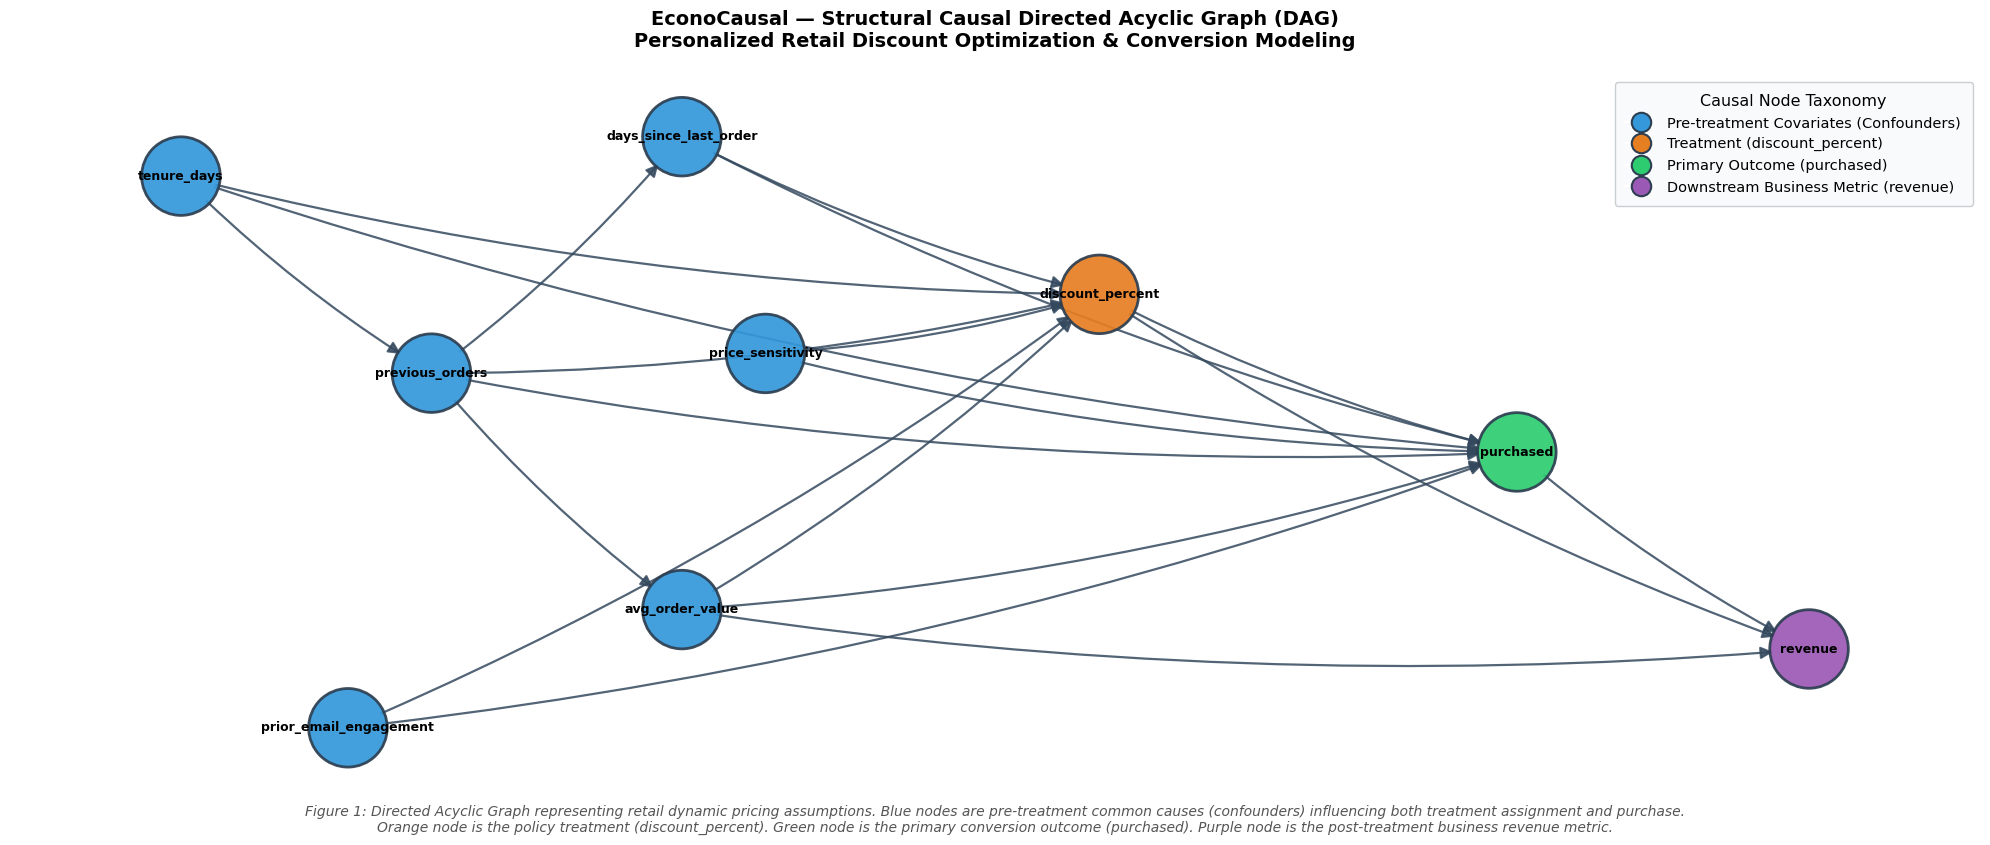


--- Optional DoWhy view_model() Check ---
DoWhy model graph initialized. Native NetworkX visualization is the primary renderer above.


<Figure size 640x480 with 0 Axes>

In [9]:
# Step 10.1: Define node classifications and custom visual aesthetics
node_categories = {
    "tenure_days": "covariate",
    "previous_orders": "covariate",
    "days_since_last_order": "covariate",
    "avg_order_value": "covariate",
    "prior_email_engagement": "covariate",
    "price_sensitivity": "covariate",
    "discount_percent": "treatment",
    "purchased": "outcome",
    "revenue": "metric",
}

# Color palette
category_colors = {
    "covariate": "#3498db",   # Professional Blue
    "treatment": "#e67e22",   # Energetic Orange
    "outcome": "#2ecc71",     # Fresh Emerald Green
    "metric": "#9b59b6",      # Elegant Purple
}

# Step 10.2: Custom hierarchical coordinates for clean, non-overlapping layout
pos = {
    "tenure_days": (0.0, 3.2),
    "previous_orders": (1.2, 2.2),
    "days_since_last_order": (2.4, 3.4),
    "avg_order_value": (2.4, 1.0),
    "prior_email_engagement": (0.8, 0.4),
    "price_sensitivity": (2.8, 2.3),
    "discount_percent": (4.4, 2.6),
    "purchased": (6.4, 1.8),
    "revenue": (7.8, 0.8),
}

# Assign colors to nodes in graph order
node_colors = [category_colors[node_categories[n]] for n in G.nodes()]

# Step 10.3: Render Causal DAG
plt.figure(figsize=(20, 9))

# Draw nodes
nx.draw_networkx_nodes(
    G, pos,
    node_color=node_colors,
    node_size=3200,
    alpha=0.92,
    edgecolors="#2c3e50",
    linewidths=2.0,
)

# Draw labels with clear white text
nx.draw_networkx_labels(
    G, pos,
    font_size=9,
    font_family="sans-serif",
    font_weight="bold",
    font_color="black",
)

# Draw directed edges with gentle curvature
nx.draw_networkx_edges(
    G, pos,
    edge_color="#34495e",
    arrows=True,
    arrowsize=18,
    arrowstyle="-|>",
    connectionstyle="arc3,rad=0.06",
    min_source_margin=26,
    min_target_margin=26,
    width=1.6,
    alpha=0.85,
)

# Step 10.4: Custom legend
legend_handles = [
    plt.Line2D([0], [0], marker='o', color='w', label='Pre-treatment Covariates (Confounders)',
               markerfacecolor='#3498db', markersize=14, markeredgecolor='#2c3e50', markeredgewidth=1.5),
    plt.Line2D([0], [0], marker='o', color='w', label='Treatment (discount_percent)',
               markerfacecolor='#e67e22', markersize=14, markeredgecolor='#2c3e50', markeredgewidth=1.5),
    plt.Line2D([0], [0], marker='o', color='w', label='Primary Outcome (purchased)',
               markerfacecolor='#2ecc71', markersize=14, markeredgecolor='#2c3e50', markeredgewidth=1.5),
    plt.Line2D([0], [0], marker='o', color='w', label='Downstream Business Metric (revenue)',
               markerfacecolor='#9b59b6', markersize=14, markeredgecolor='#2c3e50', markeredgewidth=1.5),
]

plt.legend(
    handles=legend_handles,
    loc="upper right",
    frameon=True,
    facecolor="#f8f9fa",
    edgecolor="#bdc3c7",
    fontsize=10.5,
    title="Causal Node Taxonomy",
    title_fontsize=11.5,
    borderpad=0.8,
)

plt.title(
    "EconoCausal — Structural Causal Directed Acyclic Graph (DAG)\n"
    "Personalized Retail Discount Optimization & Conversion Modeling",
    fontsize=14,
    fontweight="bold",
    pad=20,
    color="black"
)

# Caption explanation beneath the figure
plt.figtext(
    0.5, 0.02,
    "Figure 1: Directed Acyclic Graph representing retail dynamic pricing assumptions. "
    "Blue nodes are pre-treatment common causes (confounders) influencing both treatment assignment and purchase.\n"
    "Orange node is the policy treatment (discount_percent). Green node is the primary conversion outcome (purchased). "
    "Purple node is the post-treatment business revenue metric.",
    ha="center", fontsize=10, style="italic", color="#555555"
)

plt.axis("off")
plt.tight_layout(rect=[0, 0.05, 1, 0.95])
plt.show()

# Step 10.5: Safe secondary fallback for DoWhy model.view_model()
print("\n--- Optional DoWhy view_model() Check ---")
try:
    # Attempt DoWhy view_model in non-blocking mode if graphviz is available
    temp_model = CausalModel(
        data=retail_df[["discount_percent", "purchased", "days_since_last_order"]],
        treatment="discount_percent",
        outcome="purchased",
        graph="digraph { days_since_last_order -> discount_percent; days_since_last_order -> purchased; discount_percent -> purchased; }"
    )
    print("DoWhy model graph initialized. Native NetworkX visualization is the primary renderer above.")
except Exception as e:
    print(f"Note: External graphviz viewer unavailable ({type(e).__name__}). Using NetworkX/Matplotlib renderer.")
plt.tight_layout()

## 12. Assumptions, Limitations, and Week 1 Summary

### 12.1 Core Causal Assumptions Formalized
To claim that our identified estimand reflects the true causal effect, four foundational assumptions must hold:

1. **Conditional Unconfoundedness (Ignorability / No Unobserved Confounding):**
   $$(Y(t) \perp T) \mid \mathbf{W} \quad \forall t \in \mathcal{T}$$
   There are no hidden common causes of discount assignment and purchasing beyond the observed confounders in $\mathbf{W}$.
2. **Positivity (Overlap):**
   $$0 < P(T \in \mathcal{A} \mid \mathbf{W} = \mathbf{w}) < 1 \quad \forall \mathbf{w}, \mathcal{A}$$
   Every customer profile $\mathbf{w}$ has a strictly positive probability of receiving any discount level.
3. **Stable Unit Treatment Value Assumption (SUTVA):**
   - **No Interference:** Customer $i$'s purchase decision is unaffected by customer $j$'s discount offer.
   - **No Hidden Treatment Variations:** A $15\%$ discount represents the same operational promotional offer regardless of who receives it.
4. **Correct Causal Graph Specification:**
   The directional arrows in our DAG accurately represent the physical retail data-generating process.

---

### 12.2 Real-World Limitations
In live production retail environments:
- **Unobserved Factors:** Macroeconomic inflation, competitor flash sales, weather, and customer mood can introduce unobserved confounding.
- **Interference:** If stock is limited, a discount offered to one customer might cannibalize product availability for another, violating SUTVA.
- **Dynamic Feedback:** Over multi-month horizons, customer purchase history and discounts form dynamic feedback loops requiring longitudinal panel DAGs.

---


